# Control adaptativo de un doble péndulo

Simulación de un sistema de dos grados de libertad con incertidumbre paramétrica en las masas de los eslabones.

Se comparará el comportamiento de un controlador con parámetros constantes frente a uno que incorpora una ley de adaptación diseñada mediante el segundo método de Lyapunov.

In [222]:
import numpy as np
import matplotlib.pyplot as plt
import control as ct
from scipy.integrate import solve_ivp
from tqdm.auto import tqdm

plt.rcParams.update({
    'figure.figsize': (10, 5),
    'font.size': 11,
    'grid.alpha': 0.3
})

## Parámetros del modelo

Definimos los parámetros físicos del doble péndulo. Las masas de los eslabones son los parámetros desconocidos que deberá estimar el algoritmo adaptativo.

In [ ]:
# Tiempo de muestreo
Ts = 0.001

# Ancho de banda deseado del sistema
wn = np.eye(2)*5  #rad/s

# Velocidad de convergencia de identificación
rho = 1.0

# Parámetros cinemáticos
a1 = 0.4
a2 = 0.3

# Parámetros a identificar
m1_real = 5
m2_real = 2
theta_real = np.r_[m1_real,m2_real]

# Parámetros dinámicos conocidos
I0zz1 = 0.156396
mxg1  = -1.0
myg1  = 0.0
Jm1   = 0.000040
Bm1   = 0.000275
Fcm1  = 0.0

I0zz2 = 0.022723
mxg2  = -0.3
myg2  = 0.0
Jm2   = 0.000040
Bm2   = 0.000275
Fcm2  = 0.0

# Reducciones
Nr = 100.0

## Modelos de la dinámica y regresor

In [196]:
def dynamics_matrices(x, dx, theta):

    # Variables articulares
    x1, x2 = x
    dx1, dx2 = dx

    # Parámetros dinámicos desconocidos
    m1, m2 = theta

    c2 = np.cos(x2)
    s2 = np.sin(x2)

    # Matriz de inercia
    M = np.array([
        [
            I0zz1 + I0zz2 + 2*a1*mxg1 + 2*a2*mxg2
            + Jm1*Nr**2
            + a1**2*m1 + a1**2*m2 + a2**2*m2
            + 2*a1*mxg2*c2 + 2*a1*a2*m2*c2,

            I0zz2 + 2*a2*mxg2 + a2**2*m2
            + a1*mxg2*c2 + a1*a2*m2*c2
        ],
        [
            I0zz2 + 2*a2*mxg2 + a2**2*m2
            + a1*mxg2*c2 + a1*a2*m2*c2,

            I0zz2 + 2*a2*mxg2 + Jm2*Nr**2
            + a2**2*m2
        ]
    ])

    # Matriz de Coriolis y fuerzas centrífugas
    h_c = myg2*c2 + mxg2*s2 + a2*m2*s2
    C = np.array([
        [
            -a1*dx2*h_c,
            -a1*(dx1 + dx2)*h_c
        ],
        [
            a1*dx1*h_c,
            0.0
        ]
    ])

    # Vector gravitatorio
    G = np.array([
        mxg2*9.8*np.cos(x1 + x2)
        - myg2*9.8*np.sin(x1 + x2)
        + mxg1*9.8*np.cos(x1)
        - myg1*9.8*np.sin(x1)
        + m2*9.8*(a2*np.cos(x1 + x2) + a1*np.cos(x1))
        + a1*m1*9.8*np.cos(x1),

        mxg2*9.8*np.cos(x1 + x2)
        - myg2*9.8*np.sin(x1 + x2)
        + a2*m2*9.8*np.cos(x1 + x2)
    ])

    # Rozamientos
    Fr = np.array([
        Bm1*Nr**2*dx1 + Fcm1*Nr*np.tanh(dx1),
        Bm2*Nr**2*dx2 + Fcm2*Nr*np.tanh(dx2)
    ])

    return M, C, G, Fr

def inverse_dynamics(x, dx, ddx, theta):
    M, C, G, Fr = dynamics_matrices(x, dx, theta)
    #print("M=",M,"   C=",C,"  G=",G,"  Fr=",Fr)
    u = (M@ddx + C@dx + G + Fr)/Nr
    return u

def direct_dynamics(x, dx, u):
    M, C, G, Fr = dynamics_matrices(x, dx, theta_real)
    ddx = np.linalg.solve(M,Nr*u- C@dx - G - Fr)
    return ddx



In [197]:
def inverse_dynamics_regressor(x, dx, ddx):

    # Variables articulares
    x1, x2 = x
    dx1, dx2 = dx
    ddx1, ddx2 = ddx

    # Funciones trigonométricas
    c1 = np.cos(x1)
    s1 = np.sin(x1)
    c2 = np.cos(x2)
    s2 = np.sin(x2)
    c12 = np.cos(x1 + x2)
    s12 = np.sin(x1 + x2)

    # Regresor de parámetros desconocidos
    Phi = np.array([
        [
            0.0016*ddx1 + 0.0392*c1,

            0.0294*c12 + 0.0392*c1
            + 0.01*ddx1*(0.24*c2 + 0.25)
            + 0.01*ddx2*(0.12*c2 + 0.09)
            - 0.0012*dx1*dx2*s2
            - 0.0012*dx2*s2*(dx1 + dx2)
        ],
        [
            0.0,

            0.0009*ddx2 + 0.0294*c12
            + 0.0012*dx1**2*s2
            + 0.01*ddx1*(0.12*c2 + 0.09)
        ]
    ])

    # Regresor de parámetros conocidos
    Phi_kn = np.array([
        [
            0.01*ddx1,
            0.008*ddx1 + 0.098*c1,
            -0.098*s1,
            100.0*ddx1,
            100.0*dx1,
            np.tanh(dx1),
            0.01*(ddx1 + ddx2),
            0.098*c12
            + 0.01*ddx1*(0.8*c2 + 0.6)
            + 0.01*ddx2*(0.4*c2 + 0.6)
            - 0.004*dx1*dx2*s2
            - 0.004*dx2*s2*(dx1 + dx2),
            -0.098*s12
            - 0.004*dx2**2*c2
            - 0.008*ddx1*s2
            - 0.004*ddx2*s2
            - 0.008*dx1*dx2*c2,
            0.0,
            0.0,
            0.0
        ],
        [
            0.0, 0.0, 0.0, 0.0, 0.0, 0.0,
            0.01*(ddx1 + ddx2),
            0.006*ddx2 + 0.098*c12
            + 0.004*dx1**2*s2
            + 0.01*ddx1*(0.4*c2 + 0.6),
            0.004*dx1**2*c2
            - 0.098*s12
            - 0.004*ddx1*s2,
            100.0*ddx2,
            100.0*dx2,
            np.tanh(dx2)
        ]
    ])

    # Parámetros conocidos
    theta_kn = np.array([
        I0zz1, mxg1, myg1, Jm1, Bm1, Fcm1,
        I0zz2, mxg2, myg2, Jm2, Bm2, Fcm2
    ])

    # Contribución conocida
    u_kn = Phi_kn @ theta_kn

    return Phi, u_kn

In [198]:
# Pruebo si los modelos son consistentes uno con el otro

x = np.random.randn(2)
dx = np.random.randn(2)
ddx = np.random.randn(2)

Phi, u_kn = inverse_dynamics_regressor(x,dx,ddx)

print("u del modelo: ", inverse_dynamics(x,dx,ddx,theta_real) )
print("u del regresor: ", Phi@theta_real + u_kn )


u del modelo:  [ 0.16590608 -0.00637157]
u del regresor:  [ 0.16590608 -0.00637157]


## Generación de referencias (trayectoria joint)

In [147]:
def generate_reference(x_n, Td, tacc=0.2, orden=4, vmax = 50.0 * np.pi/180):

    # Condición inicial
    A = x_n[:, 0].copy()

    x_ref = []
    dx_ref = []
    ddx_ref = []

    for i in range(x_n.shape[1] - 1):

        B = x_n[:, i]
        C = x_n[:, i+1]

        DA = A - B
        DC = C - B

        T1 = max(np.max(DC / vmax), Td[i], 2*tacc)

        # Coeficientes del polinomio
        n = np.arange(orden, -1, -1)

        VA = (B-A)/tacc
        VD = (C-B)/T1

        M = np.array([(-tacc)**n])

        coef = np.ones_like(n, dtype=float)
        n_min = n.copy()

        for j in range(orden//2):
            coef *= n_min
            n_min = np.maximum(n_min-1, 0)

            M = np.vstack([
                M,
                coef * (-tacc)**n_min,
                coef * (tacc)**n_min
            ])

        rhs = np.vstack([
            A,
            VA,
            VD,
            np.zeros((orden-2, len(A)))
        ])

        p_inter = np.linalg.solve(M, rhs)

        # Zona de aceleración
        for tseg in np.arange(-tacc+Ts, tacc+1e-12, Ts):

            x_ref.append(p_inter.T @ (tseg**n))

            n1 = np.maximum(n-1, 0)
            dx_ref.append(p_inter.T @ (n*tseg**n1))

            n2 = np.maximum(n-2, 0)
            ddx_ref.append(
                p_inter.T @ (n*n1*tseg**n2)
            )

        # Zona de velocidad constante
        for tseg in np.arange(tacc+Ts, T1-tacc+1e-12, Ts):

            x_ref.append(B + DC/T1*tseg)
            dx_ref.append(DC/T1)
            ddx_ref.append(np.zeros_like(B))

        A = x_ref[-1].copy()

    # Conversión a arrays y radianes
    x_ref = np.array(x_ref).T 
    dx_ref = np.array(dx_ref).T 
    ddx_ref = np.array(ddx_ref).T 

    t = np.arange(1, x_ref.shape[1]+1)*Ts

    return t, x_ref, dx_ref, ddx_ref

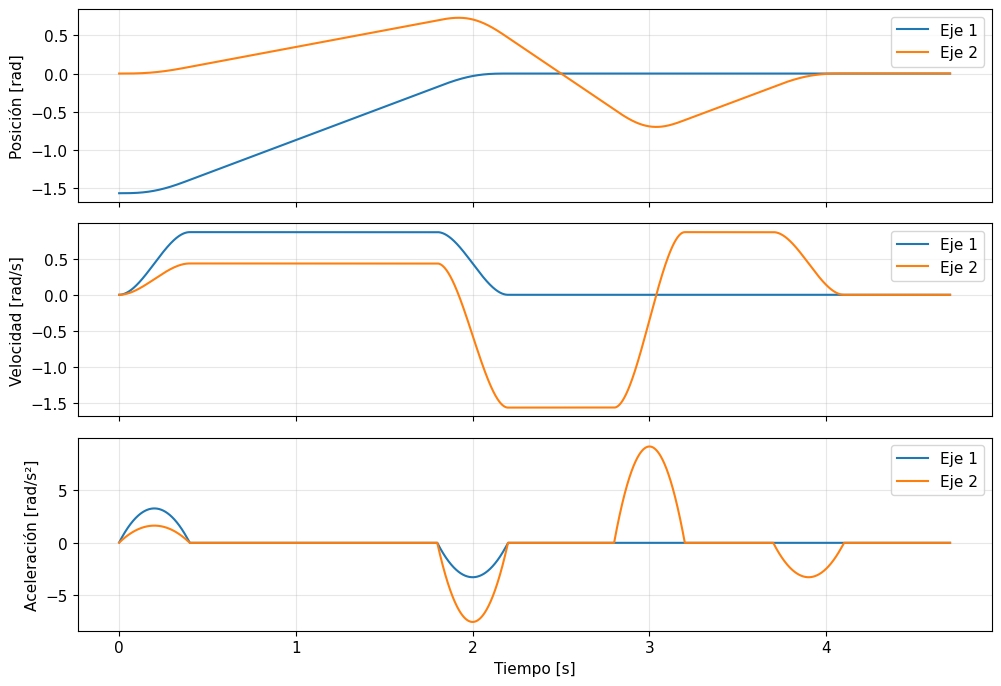

In [209]:
Td = np.array([0.0, 1.0, 0.5, 1, 1])

# Desplazamientos de cada segmento [grados]
x_n = np.array([
    [-90, 0, 0, 0, 0],
    [0,  45, -45, 0, 0]
])* np.pi/180


t, x_ref, dx_ref, ddx_ref = generate_reference(x_n,Td,orden=4)

fig, ax = plt.subplots(3, 1, sharex=True, figsize=(10, 7))

for i in range(2):
    ax[0].plot(t, x_ref[i], label=f'Eje {i+1}')
    ax[1].plot(t, dx_ref[i], label=f'Eje {i+1}')
    ax[2].plot(t, ddx_ref[i], label=f'Eje {i+1}')

ax[0].set_ylabel('Posición [rad]')
ax[1].set_ylabel('Velocidad [rad/s]')
ax[2].set_ylabel('Aceleración [rad/s²]')
ax[2].set_xlabel('Tiempo [s]')

for a in ax:
    a.grid()
    a.legend()

plt.tight_layout()
plt.show()

## Definición del control

In [ ]:
Kp = wn**2
Kd = 2*wn

print("Kp=",Kp)
print("Kd=",Kd)

def controller(x, dx, x_ref, dx_ref, ddx_ref, theta_hat):

    e = x_ref - x 
    de = dx_ref - dx 

    v = ddx_ref + Kd @ de + Kp @ e
    u = inverse_dynamics(x, dx, v, theta_hat)

    return u,v

Kp= [[25.  0.]
 [ 0. 25.]]
Kd= [[10.  0.]
 [ 0. 10.]]


## Definición de las matrices de identificación

In [241]:
# Defino las matrices del sistema linealizado con control PD
A = np.block([
    [np.zeros_like(Kp), np.eye(Kp.shape[0])],
    [-Kp,              -Kd]
])

B = np.vstack([
    np.zeros_like(Kp),
    np.eye(Kp.shape[0])
])

# Elegir una matriz definida positiva cualquiera => impacta en la Sn de Lyapunov
Q = np.eye(A.shape[0])  

P = ct.lyap(A.T, Q)  # A'P + PA + Q = 0

R_inv = np.eye(Kp.shape[0])

## Simulación del movimiento

In [ ]:
def simulate(X0,theta_hat0,adaptive=False):

    tf = t[-1]
    t_samples = np.arange(0, tf + Ts/2, Ts)

    X = X0.copy()
    theta_hat = theta_hat0.copy()

    X_hist = [X.copy()]
    u_hist = [[0,0]]
    TH_hist = [theta_hat0.copy()]

    for k in tqdm(range(len(t_samples)-1), desc="Simulación", unit="paso"):

        tk = t_samples[k]
        tk1 = t_samples[k+1]

        # Índice de referencia
        idx = min(int(round(tk/Ts)), len(t)-1)

        xr = x_ref[:, idx]
        dxr = dx_ref[:, idx]
        ddxr = ddx_ref[:, idx]

        x = X[:2]
        dx = X[2:]

        # Control
        if adaptive:
            theta_controller=theta_hat
        else:
            theta_controller=theta_hat0
        u,v = controller(x, dx, xr, dxr, ddxr, theta_controller)
        u_hist.append(u)

        # Identificación
        Phi, u_kn = inverse_dynamics_regressor(x,dx,v)
        M_hat, _, _, _ = dynamics_matrices(x, dx, theta_hat)
        theta_dot = -rho * R_inv @ Phi.T @ np.linalg.inv(M_hat).T @ B.T @ P @ X
        print(theta_dot)
        theta_hat -= Ts * theta_dot


        # Dinámica de la planta
        def ode(time, X):
            x = X[:2]
            dx = X[2:]
            ddx = direct_dynamics(x, dx, u)
            return np.r_[dx, ddx]

        sol = solve_ivp(
            ode,
            (tk, tk1),
            X,
            method='RK45',
            rtol=1e-6,
            atol=1e-8,
            t_eval=[tk1]
        )

        X = sol.y[:, -1]

        X_hist.append(X.copy())
        TH_hist.append(theta_hat.copy())

    return t_samples, np.array(X_hist), np.array(u_hist).T, np.array(TH_hist)

Simulación:   0%|          | 0/4700 [00:00<?, ?paso/s]

[0.00027149 0.00098997]
[0.00054161 0.00197492]
[0.00081034 0.00295473]
[0.00107766 0.0039293 ]
[0.00134356 0.00489854]
[0.00160802 0.00586235]
[0.00187102 0.00682063]
[0.00213255 0.00777327]
[0.00239258 0.00872019]
[0.00265112 0.0096613 ]
[0.00290813 0.01059649]
[0.0031636  0.01152568]
[0.00341752 0.01244877]
[0.00366987 0.01336568]
[0.00392064 0.01427631]
[0.00416981 0.01518058]
[0.00441738 0.0160784 ]
[0.00466331 0.01696969]
[0.00490761 0.01785437]
[0.00515025 0.01873234]
[0.00539122 0.01960352]
[0.00563051 0.02046785]
[0.00586811 0.02132523]
[0.00610399 0.02217559]
[0.00633816 0.02301885]
[0.00657059 0.02385493]
[0.00680128 0.02468376]
[0.00703021 0.02550527]
[0.00725737 0.02631938]
[0.00748274 0.02712603]
[0.00770632 0.02792513]
[0.00792809 0.02871662]
[0.00814805 0.02950044]
[0.00836617 0.03027652]
[0.00858246 0.03104478]
[0.0087969  0.03180517]
[0.00900947 0.03255763]
[0.00922017 0.03330208]
[0.009429   0.03403848]
[0.00963593 0.03476675]
[0.00984095 0.03548685]
[0.01004407 0.03

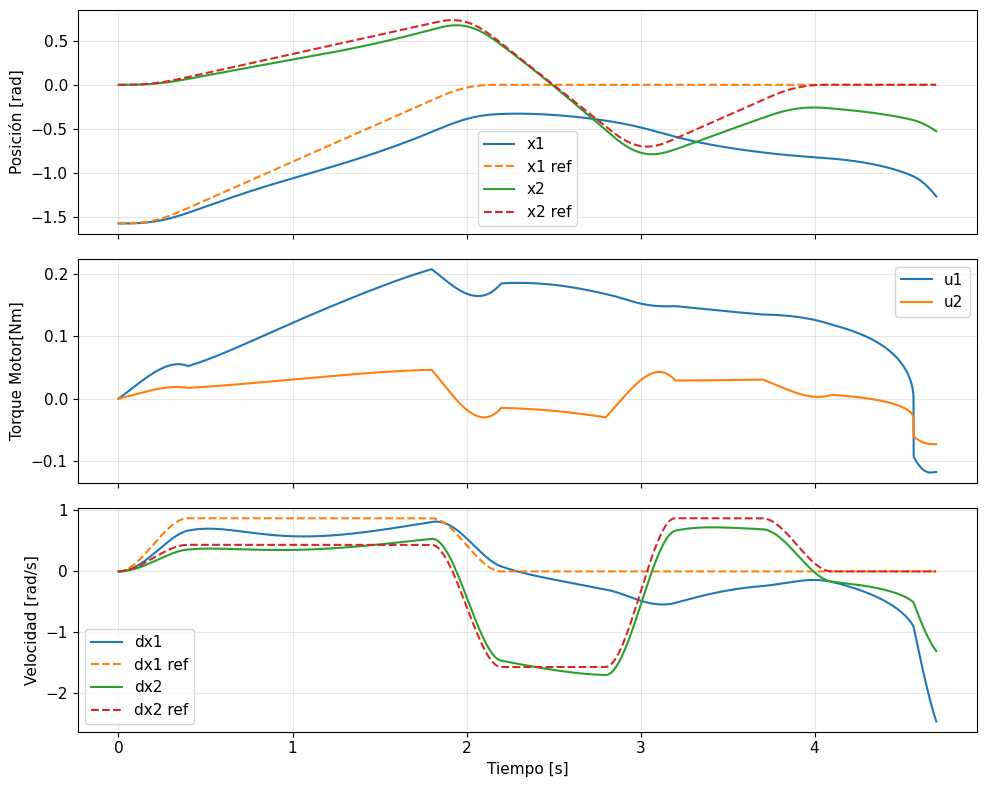

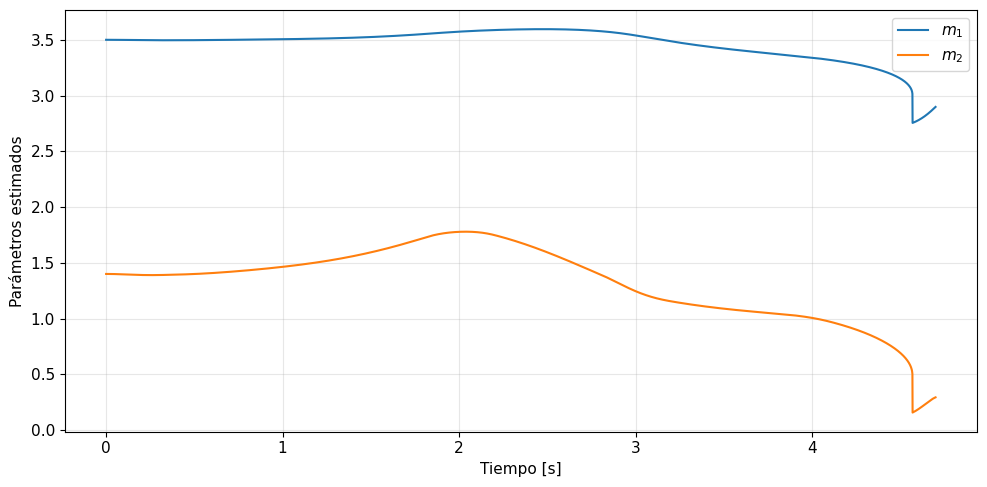

In [243]:
flag_adaptive = False
rho = 100

# Estimación inicial de las masas
theta_hat0 = np.array([m1_real, m2_real])*0.7

# Estado inicial: [x, dx]
X0 = np.r_[x_ref[:, 0], dx_ref[:, 0]]

ts, X_hist, u_hist, TH_hist = simulate(X0,theta_hat0,adaptive=flag_adaptive)

fig, ax = plt.subplots(3, 1, figsize=(10, 8), sharex=True)

for i in range(2):
    ax[0].plot(ts, X_hist[:, i], label=f'x{i+1}')
    ax[0].plot(ts[:-1], x_ref[i], '--', label=f'x{i+1} ref')

    ax[1].plot(ts, u_hist[i], label=f'u{i+1}')

    ax[2].plot(ts, X_hist[:, i+2], label=f'dx{i+1}')
    ax[2].plot(ts[:-1], dx_ref[i],  '--', label=f'dx{i+1} ref')

ax[0].set_ylabel('Posición [rad]')
ax[1].set_ylabel('Torque Motor[Nm]')
ax[2].set_ylabel('Velocidad [rad/s]')
ax[2].set_xlabel('Tiempo [s]')

for a in ax:
    a.grid()
    a.legend()

plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 5))
plt.plot(ts, TH_hist)
plt.xlabel('Tiempo [s]')
plt.ylabel('Parámetros estimados')
plt.legend([r'$m_1$', r'$m_2$'])
plt.grid()
plt.tight_layout()
plt.show()

M= [[ 0.009119 -0.067277]
 [-0.067277  0.332723]]    C= [[-0. -0.]
 [ 0.  0.]]   G= [-8.55211333e-06  0.00000000e+00]   Fr= [0.01199914 0.00599957]
[0.00436332 0.00218166]


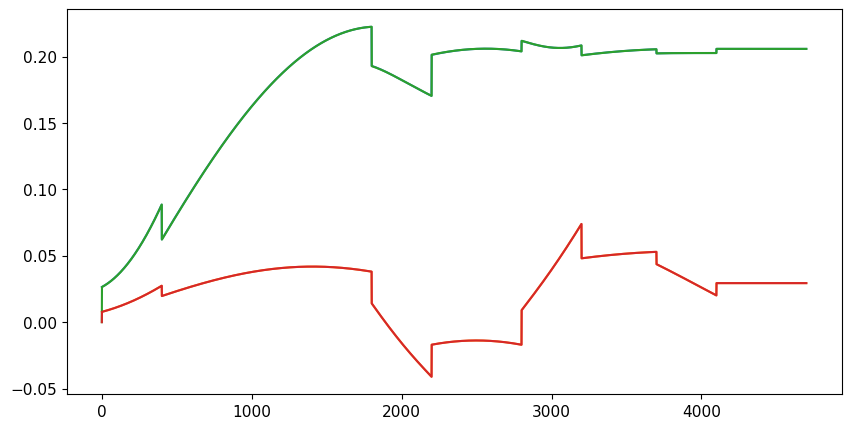

In [203]:
aa = np.zeros_like(x_ref)
for i in range(len(t)):
    aa[:,i]=inverse_dynamics(x_ref[:,i],dx_ref[:,i],ddx_ref[:,i],theta_real)
plt.plot(aa.T)
plt.plot(u_hist.T)


In [132]:
print(x_ref[:,i])

[2.45436926e-05 0.00000000e+00]
